# Instructions
Overview: **Single Animal Analysis** is where each animal's data is loaded-in and data structures (df_dfof_cells) are saved for use in future sections. In **Analysis of all cells** the behavioral data (avg manip resp across days) is loaded in for each animal and different measures are computed. To use: 
1. Run Imports
2. Change animal of Single Animal Analysis
3. Run Single Animal Analysis to end of **get dfof frames** to create df_dfof_cells for the animal
4. Run **Circle the changers..** section up to the np.save for stim_iC and nostim_iC 
5. Repeat for each animal you want to include in all cells analysis 

Once Single Animal Analysis has been run for each animal once you can skip to Analysis of all cells

### Imports

In [62]:
# import and load modules
%reload_ext autoreload
%autoreload 2

import numpy as np; import pandas as pd; import math as math; import copy
from scipy.ndimage import gaussian_filter as gaussian_filter; import scipy.stats as stats
import statsmodels.api as sm; lowess = sm.nonparametric.lowess; from skimage import transform
from scipy import sparse

#mworks imports
#from mworksbehavior import mwkfiles; from mworksbehavior.imaging import intrinsic as ii; import mworksbehavior as mwb; import mworksbehavior.mwk_io

import matplotlib as mpl; import matplotlib.pyplot as plt; import matplotlib.gridspec as gridspec; from matplotlib import cm; from matplotlib.colors import ListedColormap, LinearSegmentedColormap
#from mpl_toolkits.axes_grid1 import make_axes_locatable #from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Circle; from matplotlib.patches import Rectangle

import os, sys; from glob import glob; from pathlib import Path; import pickle
import tifffile as tfl; from datetime import date

#local files and shorthand notations for assigning common functions to variable names
sys.path.append(Path('../src').resolve().as_posix()); 
import quietcell_select_fxns_all as qcsf
r_ = np.r_; a_ = np.asarray; n_ = np.newaxis

# Single Animal Analysis

In [73]:
yr= '24'
animal_id = 'i5309'

if animal_id == 'i5214':
    dates = ['0710','0711','0712','0713','0714']
elif animal_id == 'i5309': 
    dates = ['0827','0828','0829','0830','0831']
elif animal_id == 'i5398':
    dates = ['0112','0113','0114','0115','0116'] 
    
dates_cell = ['pre']+dates+['post']
frs = ['stimFrs', 'blFrs']
rootdir = os.path.expanduser('~\\data-local\\'+animal_id)
file_path = os.path.join(rootdir,'bh-mc-reg')
mc_file_path = os.path.join(file_path,'mc')
reg_file_path = os.path.join(file_path,'reg')
file_path_suite2p = os.path.join(rootdir,'suite2p')

# Create a directory for the day to store current figures 
date_str = '\\' + str(date.today())
fig_dir = rootdir + '\\behavior_figs' + date_str

# If directory doesn't exist, create one else do nothing  
if os.path.isdir(fig_dir) is False:
    Path(fig_dir).mkdir(parents=True, exist_ok=False)
    print('dir created')
else:
    print('dir exists')

dir exists


In [74]:
#get pre and post frame df/f
# Note: "RuntimeWarning: invalid value encountered in true_divide" is caused by 0's in the baseline frames 
trained_ori_ind = 3
visResp_behavStim_pre = np.load(os.path.join(rootdir,'npys-pre\\visResp_behavStim_pre.npy'))
visResp_notStim_pre = np.load(os.path.join(rootdir,'npys-pre\\visResp_ctrl35um_pre.npy'))
i_notStimResponsive = np.where(visResp_notStim_pre[:,3] > 2.5)[0]
visResp_notStim_pre_filt = visResp_notStim_pre[i_notStimResponsive,:]

df_V_pre = np.load(os.path.join(rootdir,'npys-pre\\df_V_pre.npy'))
bl_V_pre = np.load(os.path.join(rootdir,'npys-pre\\avgPrestimV_pre.npy'))
dfof_V_pre = df_V_pre[trained_ori_ind,:,:]/bl_V_pre[trained_ori_ind,:,:]*100
dfof_V_pre_smooth = df_V_pre[trained_ori_ind,:,:]/gaussian_filter(bl_V_pre[trained_ori_ind,:,:],sigma=3)*100

visResp_behavStim_post = np.load(os.path.join(rootdir,'npys-post\\visResp_behavStim_post.npy'))
visResp_notStim_post = np.load(os.path.join(rootdir,'npys-pre\\visResp_ctrl35um_pre.npy'))
i_notStimResponsive = np.where(visResp_notStim_post[:,3] > 2.5)[0]
visResp_notStim_post_filt = visResp_notStim_post[i_notStimResponsive,:]

df_V_post = np.load(os.path.join(rootdir,'npys-post\\df_V_post.npy'))
bl_V_post = np.load(os.path.join(rootdir,'npys-post\\avgPrestimV_post.npy'))
dfof_V_post = df_V_post[trained_ori_ind,:,:]/bl_V_post[trained_ori_ind,:,:]*100
dfof_V_post_smooth = df_V_post[trained_ori_ind,:,:]/gaussian_filter(bl_V_post[trained_ori_ind,:,:],sigma=3)*100

C:\Users\Connor\Repositories\analysisConnor2025\.pixi\envs\default\lib\site-packages\ipykernel_launcher.py:21: RuntimeWarning: invalid value encountered in true_divide


### Initializing necessary data structures

In [75]:
cell_masks = np.load(os.path.join(file_path,'cell_masks.npy')) # to make this go to the pre notebook and get the cell masks

#fluorescence dataframes
df_frs_reg = pd.DataFrame(index=frs, columns=dates) #registered framestacks [frs, sidelength, sidelength]
df_cells = pd.DataFrame(index=frs, columns=dates) # avg fluor for each cell during stim or BL
avg_fluor = pd.DataFrame(index=['fluor','dfof'], columns=dates) # frame averaged fluor 
isnan_test = pd.DataFrame(index=['all','any'],columns=dates)

#dfof dataframes
df_dfof_pix = pd.DataFrame(index=['dfof'], columns=dates) # frame dfof [sidelength, sidelength]
df_dfof_pix_split = pd.DataFrame(index=['dfof'], columns=dates) # copy for split versions

df_dfof_cells = pd.DataFrame(index=['dfof'], columns=dates_cell) # cell dfof [cells]
df_dfof_cellmap = pd.DataFrame(index=['cell_map'], columns=dates_cell) # map of cells (put cells in location on fov)

In [76]:
#load pre and post cells and cellmaps
pre_cell_map = np.load(os.path.join(rootdir,'npys-pre/dFoF_map_maskV_pre_lseg.npy'))[trained_ori_ind,:,:] #only use the 90° map for this anal
df_dfof_cellmap.at['cell_map','pre'] = pre_cell_map #only use the 90° map for this anal
post_cell_map = np.load(os.path.join(rootdir,'npys-post/dFoF_map_maskV_post_lseg.npy'))[trained_ori_ind,:,:] #only use the 90° map for this anal
df_dfof_cellmap.at['cell_map','post'] = post_cell_map #only use the 90° map for this anal

# df_dfof_cells.at['dfof','pre'] = np.load(os.path.join(rootdir,'npys-pre/dfoFV_cell_pre_lseg.npy'))[:,trained_ori_ind] #only use the 90° map for this anal
# df_dfof_cells.at['dfof','post'] = np.load(os.path.join(rootdir,'npys-post/dfoFV_cell_post_lseg.npy'))[:,trained_ori_ind] #only use the 90° map for this anal

df_dfof_cells.at['dfof','pre'] = np.load(os.path.join(rootdir,'npys-pre/dfoFV_cell_pre_lseg.npy')) #only use the 90° map for this anal
df_dfof_cells.at['dfof','post'] = np.load(os.path.join(rootdir,'npys-post/dfoFV_cell_post_lseg.npy')) #only use the 90° map for this anal

### functions

In [77]:
def _im_mask_and_avg(im,masks):
    '''applies a series of masks to an image stack and returns the average value of the
    image stack within each mask across all the frames in the stack; return shape of (nCell,nFrame)'''
    nFr, nRows, nCols = im.shape
    im_vect = np.reshape(im,(nFr,nRows*nCols))
    mask_vect = np.reshape(masks,(nRows*nCols,masks.shape[2]))
    mask_sizes = mask_vect.sum(axis=(0))

    mask_vect_sparse = sparse.csr_matrix(mask_vect)
    masked_im_sums = sparse.csr_matrix.dot(im_vect,mask_vect_sparse)
    masked_im_avgs = masked_im_sums/mask_sizes[n_,:] # shape (nFrame,nCell)

    return masked_im_avgs.T # shape (nCell,nFrame)

In [78]:
def generate_dfof_map_cell(cell_masks,dfoF_cell):

    nCell = cell_masks.shape[2]

    # generate map of avg dF/F for each cell mask
    nRows = cell_masks.shape[0]
    nCols = cell_masks.shape[1]
    dFoF_map_cell_masks = np.zeros((nCell,nRows,nCols))
    for iC in range(nCell):
        cell_map = dfoF_cell[iC] * cell_masks[:,:,iC]
        cell_map[cell_map==0] = np.nan
        dFoF_map_cell_masks[iC,:,:] = cell_map

    dFoF_map_mask = np.nanmin(dFoF_map_cell_masks,axis=0)
    
    return dFoF_map_cell_masks, dFoF_map_mask,cell_map

### get fluorescence (F) dataframes

In [79]:
#make dataframe of image stacks and dataframe of cell average Fluor
for row in df_frs_reg.index:
    for col in df_frs_reg.columns:
        for file in os.listdir(reg_file_path):
            if row+'-'+col in file:
                df_frs_reg.at[row, col] = tfl.imread(os.path.join(reg_file_path,file)) #frame stack here; frs registered to eachother
                masks_frs = _im_mask_and_avg(df_frs_reg.at[row, col],cell_masks) 
                df_cells.at[row, col] = masks_frs.mean(axis=1) #avg F for each cell during stim or baseline

### get dfof dataframes
@ Connor this is a little different than how we usually look at data, it's all the stim frames in one stack, not parsed based on trial. They are in chronological order though.

In [80]:
#dfof for fr and then for the cells
fr_store = [] # place to store frame count for each day
check_bl_zeros = []

for col in df_frs_reg.columns:
    
    #do the frame one *CONNOR, this is where you edit, 
    #make an array or dataframe that doesn't take the mean across all stim frames, but instead splice it in to first and second half, etc.
    # I recommend just using all the baseline frames for a given day for all analysis, and only segregating th
    

    split_ind = int(np.ceil(df_frs_reg.at['stimFrs', col].shape[0]/2)) #taking ceil so extra frame will be in the first half 
    stim_fr = df_frs_reg.at['stimFrs', col].mean(axis=0)
    bl_fr = df_frs_reg.at['blFrs', col].mean(axis=0)
    
    df_dfof_pix.at['dfof', col] = (stim_fr-bl_fr)/(gaussian_filter(bl_fr,sigma=3))*100

    # Adding version that is split 
    stim_fr_1 = df_frs_reg.at['stimFrs', col][:split_ind,:,:].mean(axis=0)
    stim_fr_2 = df_frs_reg.at['stimFrs', col][split_ind+1:,:,:].mean(axis=0)
    
    fr_store.append([len(df_frs_reg.at['stimFrs', col][:split_ind,:,:]),len(df_frs_reg.at['stimFrs', col][split_ind+1:,:,:])])

    df_dfof_pix_split.at['dfof', col] = [(stim_fr_1-bl_fr)/(gaussian_filter(bl_fr,sigma=3))*100, 
                                   (stim_fr_2-bl_fr)/(gaussian_filter(bl_fr,sigma=3))*100]

    
    # Calculating average fluorescence across a day
    fluor = df_frs_reg.at['stimFrs', col]
    print('shape for stored fluor data: %t', fluor.shape)
    
    avg_fluor.at['fluor',col] = fluor
    store_isnan_all = []
    store_isnan_any = []
    fluor_store = []
            
    avg_fluor.at['dfof',col] = (fluor.mean(axis=(1,2))-bl_fr.mean())/bl_fr.mean()*100
                
    #print('On %s there were %i frames with all nan' %(col,len(store_isnan_all)))
    #print('On %s there were %i frames with some nan' %(col,len(store_isnan_any)))
    
    #do the cell one
    stim_cell = df_cells.at['stimFrs', col]
    bl_cell = df_cells.at['blFrs', col]
    df_dfof_cells.at['dfof', col] = (stim_cell-bl_cell)/bl_cell*100

    #put the cells on a map
    dfof_for_cell_map = df_dfof_cells.at['dfof', col]
    dFoF_map_cell_masks,dFoF_map_mask,cell_map = generate_dfof_map_cell(cell_masks,dfof_for_cell_map)
    df_dfof_cellmap.at['cell_map', col] = dFoF_map_mask
    
    #Saving df_dfof_cells for later use
    

shape for stored fluor data: %t (260, 256, 256)


C:\Users\Connor\Repositories\analysisConnor2025\.pixi\envs\default\lib\site-packages\ipykernel_launcher.py:14: RuntimeWarning: All-NaN slice encountered
  


shape for stored fluor data: %t (440, 256, 256)
shape for stored fluor data: %t (450, 256, 256)
shape for stored fluor data: %t (260, 256, 256)
shape for stored fluor data: %t (600, 256, 256)


In [81]:
# Saving df_dfof_cells for later use
df_dfof_cells.to_pickle(os.path.join(rootdir,'npys-pre/df_dfof_cells.pkl'))

### Baseline frame checking

Zeros in baseline on day %s 0710
Zeros in baseline on day %s 0711
Zeros in baseline on day %s 0712
Zeros in baseline on day %s 0713
Zeros in baseline on day %s 0714


C:\Users\Connor\Repositories\analysisConnor2025\.pixi\envs\default\lib\site-packages\ipykernel_launcher.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


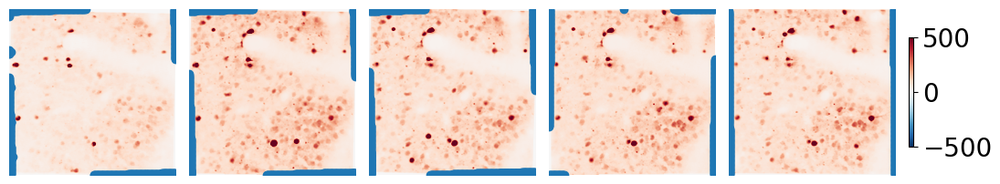

In [20]:
# Quantifying baseline data 
check_bl_zeros = []

fig, ax = plt.subplots(1, 5, figsize=(10,3))
cl=30
ax = ax.ravel()

for i,axes in enumerate(ax):
    
    day = dates[i]

    bl_fr = df_frs_reg.at['blFrs', day].mean(axis=0)
    check_bl_zeros.append(any(bl_fr.flatten() == 0)) # shows which days have 0
    axes.scatter(np.where(bl_fr == 0)[0],np.where(bl_fr == 0)[1]) # plots 0's in image
 
    if check_bl_zeros:
        print('Zeros in baseline on day %s', day)
    cl = 500 
    cmap = 'RdBu_r'
    
    
    im = axes.imshow(bl_fr,clim=(-cl,cl),cmap=cmap)
    axes.axis('off'); axes.set_xticks([]); axes.set_yticks([])
    plt.subplots_adjust(wspace=0.05, hspace=0.1)
    
    if i == 4:
        cbar_ax = fig.add_axes([1, 0.3, 0.005, 0.4])
        cbar_ax.tick_params(labelsize = 20)
        fig.colorbar(im,cax=cbar_ax)
        
plt.tight_layout()        
plt.show()

## Pixel Maps 

### Average dfof each day split in half 

In [48]:
# Reshaping each day split in half for plotting
df_dfof_pix_extend = []
for i,col in enumerate(df_dfof_pix_split):

    df_dfof_pix_extend.append(df_dfof_pix_split.iloc[0,i][0])
    df_dfof_pix_extend.append(df_dfof_pix_split.iloc[0,i][1])

C:\Users\Connor\Repositories\analysisConnor2025\.pixi\envs\default\lib\site-packages\ipykernel_launcher.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


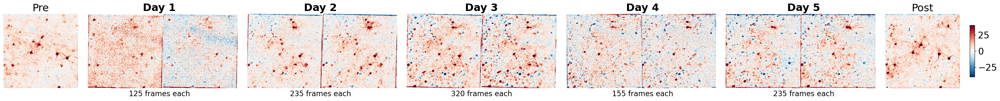

In [75]:
# Plotting dfof frame maps for each day split in half 
fig = plt.figure(figsize=(30, 4))  # Adjust figure size

# Define grid layout
gs = gridspec.GridSpec(1, 7, figure=fig, width_ratios=[1, 2, 2, 2, 2, 2, 1])

cl = 40
cmap = 'RdBu_r'

# First subplot (single)
ax1 = fig.add_subplot(gs[0])
ax1.imshow(dfof_V_pre_smooth,clim=(-cl,cl),cmap=cmap)
ax1.set_title("Pre",fontsize = 23)
ax1.axis('off'); ax1.set_xticks([]); ax1.set_yticks([])

# Middle 5 columns each containing two subplots side by side
index_first_half = [0,2,4,6,8]
middle_axes = []

for i in range(1, 6):  # Columns 1 to 5
    subgrid = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[i], wspace=0)  # 1 row, 2 columns
  
    ax_left = fig.add_subplot(subgrid[0])   # Left subplot
    ax_right = fig.add_subplot(subgrid[1])  # Right subplot
    
    # Plotting the data split in half for each day 
    ax_left.imshow(df_dfof_pix_extend[index_first_half[i-1]],clim=(-cl,cl),cmap=cmap)
    ax_right.imshow(df_dfof_pix_extend[index_first_half[i-1]+1],clim=(-cl,cl),cmap=cmap)

    ax_left.axis('off'); ax_left.set_xticks([]); ax_left.set_yticks([])
    ax_right.axis('off'); ax_right.set_xticks([]); ax_right.set_yticks([])
    
    fig.text(0.17 + 0.165 * (i - 1), 0.81, f"Day {i}", ha='center', fontsize=23, fontweight='bold')
    fig.text(0.17 + 0.165 * (i - 1), 0.15, f"{fr_store[i-1][0]} frames each", ha='center', fontsize=16)

    middle_axes.append((ax_left, ax_right))
    
# Last subplot (single)
ax7 = fig.add_subplot(gs[6])
im = ax7.imshow(dfof_V_post_smooth,clim=(-cl,cl),cmap=cmap)
ax7.set_title("Post",fontsize = 23)
ax7.axis('off'); ax7.set_xticks([]); ax7.set_yticks([])
cbar_ax = fig.add_axes([1, 0.3, 0.005, 0.4])
cbar_ax.tick_params(labelsize = 20)
fig.colorbar(im,cax=cbar_ax)

# Example styling
# for i, (ax_left, ax_right) in enumerate(axs_middle, start=1):
#     ax_left.set_title(f"Left {i}")
#     ax_right.set_title(f"Right {i}")

    
plt.tight_layout()
plt.show()

# Output save
name = '%s_split_across_days.png' %animal_id
fig.savefig(os.path.join(fig_dir,name), bbox_inches='tight', dpi=400)


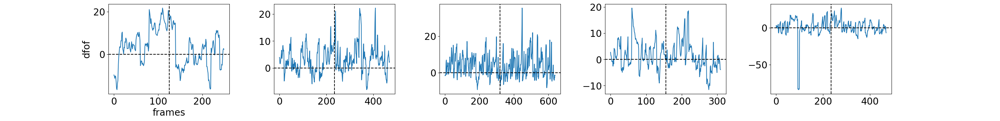

In [84]:
# Creating line plots of average dfof across the pixel maps for each day 

# Create figure
fig = plt.figure(figsize=(30, 4))  # Adjust figure size

# Define grid layout
gs = gridspec.GridSpec(1, 7, figure=fig, width_ratios=[1, 2, 2, 2, 2, 2, 1])

# First subplot (single)
ax1 = fig.add_subplot(gs[0])
ax1.axis('off'); ax1.set_xticks([]); ax1.set_yticks([])

# Middle 5 columns each containing two subplots side by side
index_first_half = [0,2,4,6,8]
middle_axes = []
cl = 40
for i in range(1, 6):  # Columns 1 to 5
    
    ax_mid = fig.add_subplot(gs[i])
    ax_mid.plot(avg_fluor.at['dfof',dates[i-1]])    
    ax_mid.axvline(fr_store[i-1][0],c='black',linestyle='--')
    ax_mid.axhline([0],c='black',linestyle='--')

    plt.rcParams.update({'font.size': 20})

    if i == 1:
        ax_mid.set_xlabel("frames")
        ax_mid.set_ylabel("dfof")
    
# Last subplot (single)
ax7 = fig.add_subplot(gs[6])
ax7.axis('off'); ax7.set_xticks([]); ax7.set_yticks([])

plt.tight_layout()
plt.show()

# Output save
name = 'dfof_across_days.png'
fig.savefig(os.path.join(fig_dir,name), bbox_inches='tight', dpi=400)

C:\Users\Connor\Repositories\analysisConnor2025\.pixi\envs\default\lib\site-packages\ipykernel_launcher.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


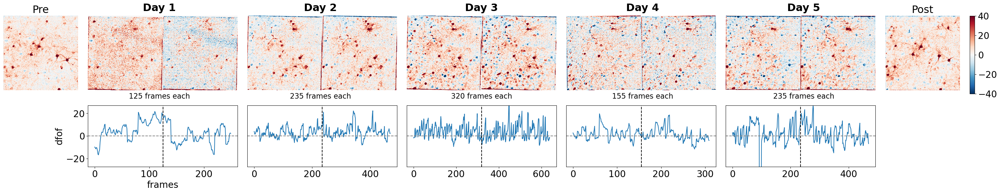

In [85]:
# Combining the two above plots
# Create figure
fig = plt.figure(figsize=(30, 6))  # Adjust figure size

# Define grid layout
gs = gridspec.GridSpec(2, 7, figure=fig, width_ratios=[1, 2, 2, 2, 2, 2, 1], height_ratios = [2,1])

cl = 40
cmap = 'RdBu_r'

# First subplot (single)
ax1 = fig.add_subplot(gs[0])
ax1.imshow(dfof_V_pre_smooth,clim=(-cl,cl),cmap=cmap)
ax1.set_title("Pre",fontsize = 23)
ax1.axis('off'); ax1.set_xticks([]); ax1.set_yticks([])

# Middle 5 columns each containing two subplots side by side
index_first_half = [0,2,4,6,8]
middle_axes = []

for i in range(1, 6):  # Columns 1 to 5
    subgrid = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[i], wspace=0, hspace =0)  # 1 row, 2 columns
  
    ax_left = fig.add_subplot(subgrid[0])   # Left subplot
    ax_right = fig.add_subplot(subgrid[1])  # Right subplot
    
    ax_left.imshow(df_dfof_pix_extend[index_first_half[i-1]],clim=(-cl,cl),cmap=cmap)
    ax_right.imshow(df_dfof_pix_extend[index_first_half[i-1]+1],clim=(-cl,cl),cmap=cmap)

    ax_left.axis('off'); ax_left.set_xticks([]); ax_left.set_yticks([])
    ax_right.axis('off'); ax_right.set_xticks([]); ax_right.set_yticks([])
    
    fig.text(0.17 + 0.165 * (i - 1), 0.85, f"Day {i}", ha='center', fontsize=23, fontweight='bold')
    fig.text(0.17 + 0.165 * (i - 1), 0.40, f"{fr_store[i-1][0]} frames each", ha='center', fontsize=16)

    middle_axes.append((ax_left, ax_right))
    
# Last subplot (single)
ax7 = fig.add_subplot(gs[6])
im = ax7.imshow(dfof_V_post_smooth,clim=(-cl,cl),cmap=cmap)
ax7.set_title("Post",fontsize = 23)
ax7.axis('off'); ax7.set_xticks([]); ax7.set_yticks([])
cbar_ax = fig.add_axes([1, 0.425, 0.005, 0.4])
cbar_ax.tick_params(labelsize = 20)
fig.colorbar(im,cax=cbar_ax)
    
# First subplot second row  (single)
ax8 = fig.add_subplot(gs[7])
ax8.axis('off'); ax1.set_xticks([]); ax1.set_yticks([])

row_shift = 7
# Middle 5 columns each containing two subplots side by side
for i in range(1+row_shift, 6+row_shift):  # Columns 1 to 5
    subgrid = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[i], wspace=1, hspace =0)  # 1 row, 2 columns

    ax = fig.add_subplot(gs[i])
    ax.plot(avg_fluor.at['dfof',dates[i-1-row_shift]])    
    ax.axvline(fr_store[i-1-row_shift][0],c='black',linestyle='--')
    ax.axhline([0],c='gray',linestyle='--')
    ax.axis("off")
    plt.rcParams.update({'font.size': 20})
    
# Last subplot (single)
ax14 = fig.add_subplot(gs[13])
ax14.axis('off'); ax14.set_xticks([]); ax14.set_yticks([])    
plt.tight_layout()

# Finding max value of dfof across all days to set y range
data = []
for day in dates: 
    data.append(avg_fluor.loc['dfof',day])
    
data = np.concatenate(data)
data = np.sort(data)
min_range = data[3]
max_range = data[-3]

# Adding axes back in manually to keep spacing! 
for i in range(1+row_shift, 6+row_shift):  # Columns 1 to 5
    ax = fig.add_subplot(gs[i])
    ax.axis("on")  # Re-enable axis visibility
    ax.plot(avg_fluor.at['dfof',dates[i-1-row_shift]])    
    ax.axvline(fr_store[i-1-row_shift][0],c='black',linestyle='--')
    ax.axhline([0],c='gray',linestyle='--')
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.set_ylim([-max_range, max_range])

    if i == 1+row_shift:
        ax.set_xlabel("frames")
        ax.set_ylabel("dfof")
        
    if i > 1+row_shift:
        ax.set_yticks([])
        
   
    # Check
    # if i == 5+row_shift:
    #     ax.set_yticks([min_range, max_range])

plt.show()


# Output save
name = 'split_across_days_double.png'
fig.savefig(os.path.join(fig_dir,name), bbox_inches='tight', dpi=400)


In [16]:
# mean1 = np.nanmean(avg_fluor.at['dfof',dates[0]],axis=1)
# out = np.isinf(mean1)
# vals = np.where(out)

# #Plotting where inf in first mean
# plt.scatter(np.where(out==True)[0],np.where(out==True)[1])
# plt.title("Inf Values in Matrix Before Averaging Over the Final Dim")

# print(mean1.shape)
# print("Values of nanmean across dim1:\n")
# print(mean1)
# print(mean2.shape)
# print("nValues of nanmean across final average:\n")
# mean2 = np.nanmean(mean1,axis=1)
# print(mean2)


### dif frame maps

C:\Users\Connor\Repositories\analysisConnor2025\.pixi\envs\default\lib\site-packages\ipykernel_launcher.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


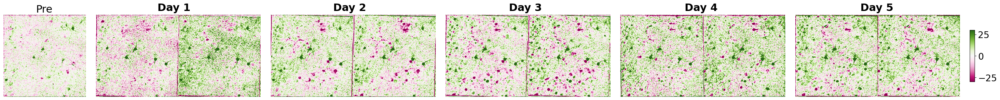

In [87]:
# Create figure
fig = plt.figure(figsize=(30, 4))  # Adjust figure size

# Define grid layout
gs = gridspec.GridSpec(1, 6, figure=fig, width_ratios=[1, 2, 2, 2, 2, 2])
cl = 30

# First subplot (single)
ax1 = fig.add_subplot(gs[0])
ax1.imshow(dfof_V_post-dfof_V_pre,clim=(-cl,cl),cmap='PiYG')
ax1.set_title("Pre",fontsize = 23)
ax1.axis('off'); ax1.set_xticks([]); ax1.set_yticks([])

# Middle 5 columns each containing two subplots side by side
index_first_half = [0,2,4,6,8]
middle_axes = []

for i in range(1, 6):  # Columns 1 to 5
    subgrid = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[i], wspace=0)  # 1 row, 2 columns
  
    ax_left = fig.add_subplot(subgrid[0])   # Left subplot
    ax_right = fig.add_subplot(subgrid[1])  # Right subplot
    
    ax_left.imshow(dfof_V_post-df_dfof_pix_extend[index_first_half[i-1]],clim=(-cl,cl),cmap='PiYG')
    ax_right.imshow(dfof_V_post-df_dfof_pix_extend[index_first_half[i-1]+1],clim=(-cl,cl),cmap='PiYG')

    ax_left.axis('off'); ax_left.set_xticks([]); ax_left.set_yticks([])
    ax_right.axis('off'); ax_right.set_xticks([]); ax_right.set_yticks([])
    
    fig.text(0.185 + 0.18 * (i - 1), 0.85, f"Day {i}", ha='center', fontsize=23, fontweight='bold')
    
    if i == 5:
        im = ax_right.imshow(dfof_V_post-df_dfof_pix_extend[index_first_half[i-1]+1],clim=(-cl,cl),cmap='PiYG')
        cbar_ax = fig.add_axes([1, 0.3, 0.005, 0.4])
        cbar_ax.tick_params(labelsize = 20)
        fig.colorbar(im,cax=cbar_ax)

# Example styling
# for i, (ax_left, ax_right) in enumerate(axs_middle, start=1):
#     ax_left.set_title(f"Left {i}")
#     ax_right.set_title(f"Right {i}")
    
plt.tight_layout()
plt.show()

# Output save
name = 'diff_split_across_days.png'
fig.savefig(os.path.join(fig_dir,name), bbox_inches='tight', dpi=400)

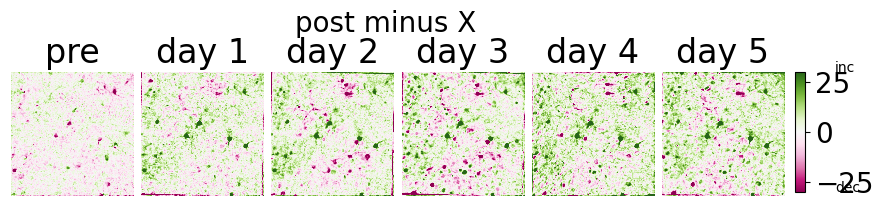

In [63]:
fig, ax = plt.subplots(1, 6, figsize=(10,3))
cl=30
ax = ax.ravel()
for i,axes in enumerate(ax):
    cl=30
    if i > 0:
        axes.imshow(dfof_V_post-df_dfof_pix.iloc[0, i-1],clim=(-cl,cl),cmap='PiYG')
        axes.set_title('day '+str(i))
    else:
        im = axes.imshow(dfof_V_pre-dfof_V_post,clim=(-cl,cl),cmap='PiYG')
        axes.set_title('pre')
        cbar_ax = fig.add_axes([0.91, 0.3, 0.01, 0.4])
        #cbar = fig.colorbar(cm.ScalarMappable(cmap='PiYG'), ax=axes, ticks=[0, 1], shrink=0.95, pad=0.02)
        fig.colorbar(im,cax=cbar_ax)
    axes.axis('off'); axes.set_xticks([]); axes.set_yticks([])
plt.text(-50,50,'post minus X',fontsize=20)
plt.text(4,30,'inc',fontsize=10)
plt.text(4,-30,'dec',fontsize=10)
plt.subplots_adjust(wspace=0.05, hspace=0.1)
#plt.savefig(os.path.join(fig_dir,'postminusX.png'), bbox_inches='tight', dpi=400)

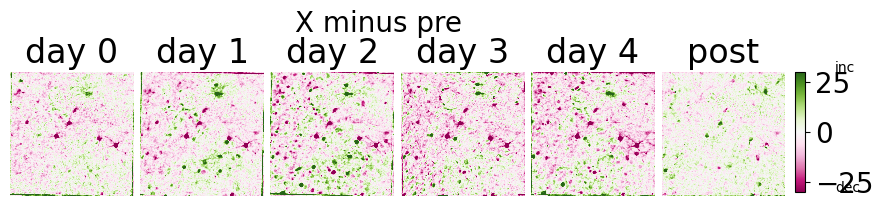

In [64]:
fig, ax = plt.subplots(1, 6, figsize=(10,3))
cl=30
ax = ax.ravel()

for i,axes in enumerate(ax):
    cl=30
    
    if i < 5:
        axes.imshow(df_dfof_pix.iloc[0, i]-dfof_V_pre,clim=(-cl,cl),cmap='PiYG')
        axes.set_title('day '+str(i))
    else:
        im = axes.imshow(dfof_V_post-dfof_V_pre,clim=(-cl,cl),cmap='PiYG')
        axes.set_title('post')
        cbar_ax = fig.add_axes([0.91, 0.3, 0.01, 0.4])
        fig.colorbar(im,cax=cbar_ax)
        
    axes.axis('off'); axes.set_xticks([]); axes.set_yticks([])
        
plt.text(-50,50,'X minus pre',fontsize=20)
plt.text(4,30,'inc',fontsize=10)
plt.text(4,-30,'dec',fontsize=10)
plt.subplots_adjust(wspace=0.05, hspace=0.1)
    #plt.savefig(os.path.join(fig_dir,'xminuspre.png'), bbox_inches='tight', dpi=400)

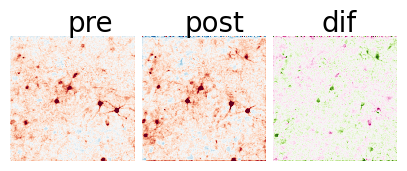

In [88]:
fig, ax = plt.subplots(1,3,figsize=(5,2))
cl=40;ax = ax.ravel()
ax[0].imshow(dfof_V_pre,clim=(-cl,cl),cmap='RdBu_r')
ax[1].imshow(dfof_V_post,clim=(-cl,cl),cmap='RdBu_r')
ax[2].imshow(dfof_V_post-dfof_V_pre,clim=(-cl,cl),cmap='PiYG')
ax[0].axis('off');ax[1].axis('off');ax[2].axis('off')
plt.text(-420,-10,'pre');plt.text(-180,-10,'post');plt.text(100,-10,'dif')
plt.subplots_adjust(wspace=0.05, hspace=0.1)
plt.savefig(os.path.join(fig_dir,'prepostdiff.png'), bbox_inches='tight', dpi=400)

## Diff cell maps

In [70]:
df_delta_dfof_bh_map = pd.DataFrame(index=['cell_map'], columns=dates) # change from day 1 of behavior
df_delta_dfof_bh = pd.DataFrame(index=['dfof'], columns=dates) # change from day 1 of behavior

for col in df_delta_dfof_bh_map.columns:
    df_delta_dfof_bh_map.at['cell_map',col] = df_dfof_cellmap.at['cell_map',col]-df_dfof_cellmap.at['cell_map',dates[0]]
    df_delta_dfof_bh.at['dfof',col] = df_dfof_cells.at['dfof',col]-df_dfof_cells.at['dfof',dates[0]]


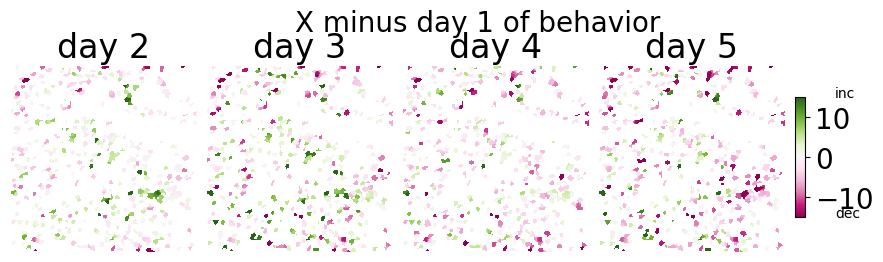

In [71]:
fig, ax = plt.subplots(1, 4, figsize=(10,3))
cl=15
ax = ax.ravel()
for i,axes in enumerate(ax):
    im = axes.imshow(df_delta_dfof_bh_map.iloc[0,i+1],clim=(-cl,cl),cmap='PiYG')
    axes.set_title('day '+str(i+2))
    if i == 1:
        cbar_ax = fig.add_axes([0.91, 0.3, 0.01, 0.4])
        fig.colorbar(im,cax=cbar_ax)
    axes.axis('off'); axes.set_xticks([]); axes.set_yticks([])
plt.text(-50,cl*2.1,'X minus day 1 of behavior',fontsize=20)
plt.text(4,cl,'inc',fontsize=10)
plt.text(4,-cl,'dec',fontsize=10)
plt.subplots_adjust(wspace=0.05, hspace=0.1)
#plt.savefig(os.path.join(fig_dir,'xminuspre.png'), bbox_inches='tight', dpi=400)

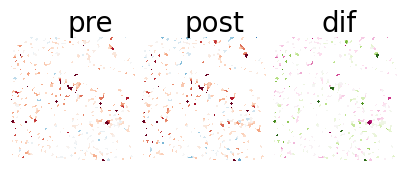

In [73]:
post_pre_dif_map = df_dfof_cellmap.at['cell_map','post']-df_dfof_cellmap.at['cell_map','pre']

fig, ax = plt.subplots(1,3,figsize=(5,2));cl=20;ax = ax.ravel()
ax[0].imshow(df_dfof_cellmap.at['cell_map','pre'],clim=(-cl,cl),cmap='RdBu_r')
ax[1].imshow(df_dfof_cellmap.at['cell_map','post'],clim=(-cl,cl),cmap='RdBu_r')
ax[2].imshow(post_pre_dif_map,clim=(-cl,cl),cmap='PiYG')
plt.text(-420,-10,'pre',size=20);plt.text(-180,-10,'post',size=20);plt.text(100,-10,'dif',size=20)
ax[0].axis('off');ax[1].axis('off');ax[2].axis('off')
plt.subplots_adjust(wspace=0.05, hspace=0.1)

## Circle the changers (can also use the "pattern_coords" array to circle the stim cells)

In [78]:
cell_coords = []
for iC in range(cell_masks.shape[2]):
    ys,xs = np.where(cell_masks[:,:,iC]>0)
    coord = [np.average(xs),np.average(ys)]
    cell_coords.append(coord)

In [79]:
exp_params = pickle.load(open(os.path.join(file_path_suite2p,'expt_params.pkl'),'rb')); #print('\npre_params)

In [80]:
## Run up to this point to get the stim/nostim iCs
with qcsf.analysis_2p_general(file_path=file_path_suite2p,expt_params=exp_params) as q2pg:
    cell_coords,pattern_coords,conversion_factor = q2pg.calculate_cell_pattern_coords(rootdir,cell_masks,csv_pattern_filename='quiet.csv')
    stim_iC,nostim_iC,all_iC = q2pg.label_stimulated_cells(cell_coords,pattern_coords,radius_microns=10) #0.5 pix/um 2x; 0.616 pix/um 2.5x

np.save(os.path.join(rootdir,'npys-pre/stim_iC.npy'),stim_iC)
np.save(os.path.join(rootdir,'npys-pre/nostim_iC.npy'),nostim_iC)
    
print("how many stimulated cells?", len(stim_iC))
print("how many stimulated spots?", len(pattern_coords))

zoom = 2.5. Finding cell IDs within direct stimulation radius... Stimulated cell IDs found.
how many stimulated cells? 21
how many stimulated spots? 15


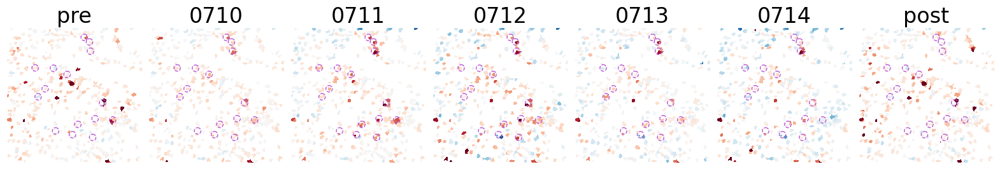

In [81]:
shift_x = 0
shift_y = 0
fig, ax = plt.subplots(1, 7, figsize=(20,6)); cl=40
for i,axes in enumerate(ax):
    axes.imshow(df_dfof_cellmap.iloc[0,i],clim=(-cl,cl),cmap='RdBu_r')
    axes.axis('off'); axes.set_xticks([]); axes.set_yticks([])
    for coords in pattern_coords:
        axes.add_patch( Circle((coords[0]+shift_x,coords[1]+shift_y),radius=10*conversion_factor,fill=False,ec='mediumorchid',ls='--',lw=1,alpha=1) )
    axes.set_title(df_dfof_cellmap.columns[i])
plt.subplots_adjust(wspace=0.05, hspace=0.1)
plt.savefig(os.path.join(fig_dir,'top_changers_circled.png'), bbox_inches='tight', dpi=400)

# Analysis of all cells
This code loads the 'df_dfof_cells' for each animal (produced above), and stores the data in a dataframe for further analysis. It also creates a df that holds indices of cells in defined categories, "across_days" stores the average manipulated dfof value for each day, this is useful for plotting changes over time. See comments for other column heading explanations. **Note**: all plots across days show the 90 deg (manip) response.

## Set-up

In [82]:
# Assigning root directory
rootdir = os.path.expanduser('~\\data-local')

# Create a directory for the current day to store current figures 
date_str = '\\' + str(date.today())
fig_dir = rootdir + '\\behavior_figs' + date_str 
                            
# Create a If directory doesn't exist, create one else do nothing  
if os.path.isdir(fig_dir) is False:
    Path(fig_dir).mkdir(parents=True, exist_ok=False)
    print('dir created')
else:
    print('dir exists')

# Loading in all df_dfof_cells 
animals = ['i5214','i5309']
# Creating a list of strings for col names
days = np.array(list(range(1,6)))
days = np.char.add("Day ",days.astype(str))
behavior_days = days.tolist()
days = ['pre'] + behavior_days + ['post']

dfof_cells_all = pd.DataFrame(index=['trained','untrained'], columns=days) # cell dfof [cells]


for i, animal in enumerate(animals): 
    data_dir = rootdir + "\\" + animal + '\\npys-pre'
    # os.path.expanduser('~/data-local/'+animal+'/npys_pre/df_dfof_cells.pkl')
    df = pd.read_pickle(data_dir +'\\df_dfof_cells.pkl')
    df.columns = days
    
    stim_iC = np.load(data_dir +'\\stim_iC.npy')  
    nostim_iC = np.load(data_dir +'\\nostim_iC.npy')
    
    for col in dfof_cells_all.columns:
        
        if i == 0:
            if col == 'pre' or col == 'post':
                dfof_cells_all.at['trained',col] = df[col][0][stim_iC,:]
                dfof_cells_all.at['untrained',col] = df[col][0][nostim_iC,:]
            else: 
                dfof_cells_all.at['trained',col] = df[col][0][stim_iC]
                dfof_cells_all.at['untrained',col] = df[col][0][nostim_iC]
        else:
            if col == 'pre' or col == 'post':
                dfof_cells_all.at['trained',col] = np.concatenate((dfof_cells_all.at['trained',col], df[col][0][stim_iC,:]),axis=0)
                dfof_cells_all.at['untrained',col] = np.concatenate((dfof_cells_all.at['untrained',col], df[col][0][nostim_iC,:]),axis=0)
            else: 
                dfof_cells_all.at['trained',col] = np.concatenate((dfof_cells_all.at['trained',col], df[col][0][stim_iC]),axis=0)
                dfof_cells_all.at['untrained',col] = np.concatenate((dfof_cells_all.at['untrained',col], df[col][0][nostim_iC]),axis=0)


dir exists


In [83]:
# Goal: line plot of the dfof most enhanced and suppressed cells over the 5 days (set by threshold)
# Creating a df that holds indices of cells in defined categories, can add to this list for future analysis 
index_df = pd.DataFrame(index=['trained','untrained'],columns=['high','low','across_days','high_dict','low_dict','high_num','low_num'])

# Minimum percent change b/t first and last day to be included in high and low groups 
p_threshold = 0.3

for i,cell_class in enumerate(index_df.index):
    
    # Grab create array of stim_cell x day
    data = []
    for day in behavior_days: 
        data.append(dfof_cells_all.at[cell_class,day])

    # Finding the indices of the cells with the greatest difference between the first and the last day
    diff = data[-1:]-data[0]
    diff = diff[0]
    
    # find num of cells defined by top and bottom threshold
    n = int(np.ceil(len(diff)*p_threshold))

    # Sorting array by index not by value 
    sorted_index_array = np.argsort(diff)
    
    # Finding responders (most postive and negative change)
    index_df.at[cell_class,'high'] = sorted_index_array[-n:]
    index_df.at[cell_class,'low'] = sorted_index_array[1:n]        
    index_df.at[cell_class,'across_days'] = np.array(data)
    

## Determine quiet cells and other categories
Where:
quiet cells never acquired a tuning,
no change cells are cells whose maximum change is less than 10% (could be quiet initially or not),
non plastic cells have an initial response and didn't change it 

In [4]:
# Calculating the number of quiet cells in our data
quiet_cell_thresh = 10 # percent

pre_data = dfof_cells_all.at['trained','pre']
post_data = dfof_cells_all.at['trained','post']

pre_minus_post = post_data - pre_data

# Cells with <10% dfof at all angles
pre_quiet_cells = [np.all(np.abs(pre_data[row]) < quiet_cell_thresh) for row in range(pre_data.shape[0])]
post_quiet_cells = [np.all(np.abs(post_data[row]) < quiet_cell_thresh) for row in range(post_data.shape[0])]

# Cells that never had or acquired a tuning 
stay_quiet_cells = np.logical_and(pre_quiet_cells,post_quiet_cells)

# Finding cells that didn't change
no_change_cells = np.array([np.all(np.abs(pre_minus_post[row]) < 10) for row in range(pre_minus_post.shape[0])])

# Not quiet, didn't change
non_plastic_cells = np.where((no_change_cells) & (~stay_quiet_cells))[0]

print("Number of non-plastic cells: %i" % len([i for i, x in enumerate(non_plastic_cells) if x]))

Number of non-plastic cells: 6


([<matplotlib.patches.Wedge at 0x1cbc75c1b48>,
 [Text(-0.06167746258165048, 1.0982694981695018, 'quiet'),
  Text(-0.9910657786312885, -0.4772720633202386, 'non-plastic'),
  Text(0.4209517280266836, -1.0162675054685892, 'plastic')],
 [Text(-0.03364225231726389, 0.5990560899106373, '51.8%'),
  Text(-0.5405813337988846, -0.2603302163564937, '10.7%'),
  Text(0.22961003346910014, -0.5543277302555941, '37.5%')])

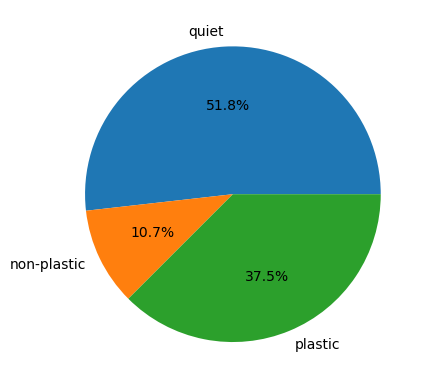

In [5]:
# Pie chart of quiet, non-plastic, and plastic cells
num_quiet = len(np.where(stay_quiet_cells)[0])
num_nonp = len(np.where(non_plastic_cells)[0])
num_no_change = len(np.where(no_change_cells)[0])

# Calculating number of cells that were plastic 
num_change = len(stay_quiet_cells) - num_no_change - num_nonp

labels = 'quiet','non-plastic','plastic'
sizes = [num_quiet, num_nonp, num_change]

fig, ax = plt.subplots()
ax.pie(sizes, labels=labels,autopct='%1.1f%%')

## Trends in cell response during behavior

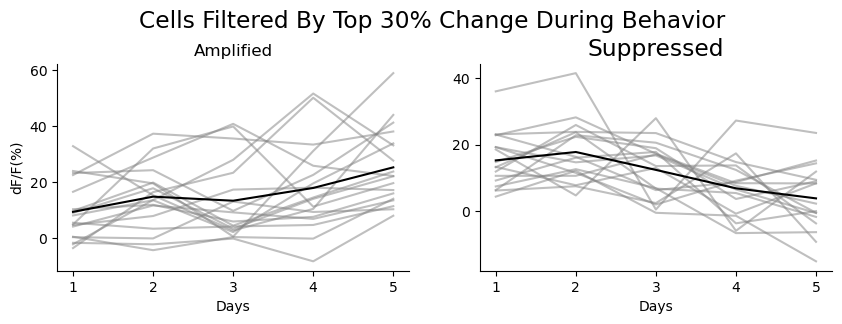

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10,3))
ax = axes.ravel()

cell_type = 'trained'
groups = ['high','low']
titles = ["Amplified", "Suppressed"]
for i, ax in enumerate(axes):
    
    # Amp and Suppressed During Behavior
    group = groups[i]
    
    # Plot highest responders 
    ax.plot(index_df.at[cell_type,'across_days'][:,index_df.at[cell_type,group]],color='grey',alpha=0.5)
    ax.plot(index_df.at[cell_type,'across_days'][:,index_df.at[cell_type,group]].mean(axis=1),color='black',lw=1.5)
    ax.set_xticks([0,1,2,3,4])
    ax.set_xticklabels([1,2,3,4,5])
    ax.set_xlabel("Days")
    ax.spines[['right', 'top']].set_visible(False)
    ax.set_title(titles[i])
    plt.rcParams.update({'font.size': 14})
    
    if i == 0:
        ax.set_ylabel("dF/F(%)") 


fig.subplots_adjust(top=0.80)
val = p_threshold*100
fig.suptitle("Cells Filtered By Top %i%% Change During Behavior" % val) 
plt.savefig(os.path.join(fig_dir,'biggest_behavior_change.png'), bbox_inches='tight', dpi=400)

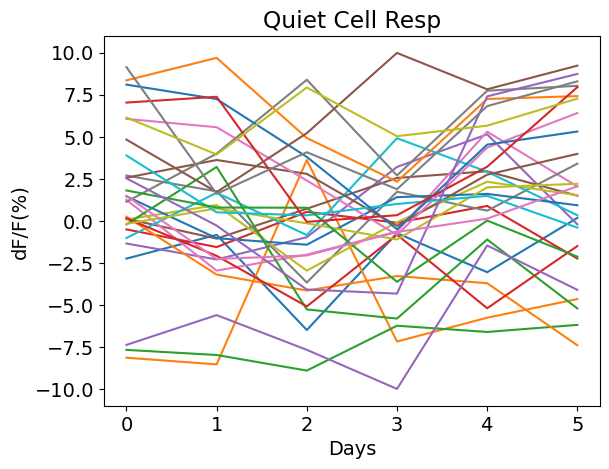

In [7]:
# Check behavior response of cells that stayed quiet
data = dfof_cells_all.at['trained','pre'][stay_quiet_cells,:]
for cell in range(data.shape[0]):
    plt.plot(data[cell,:])
    plt.xlabel("Days")
    plt.ylabel("dF/F(%)") 
    plt.title("Quiet Cell Resp")

## Pre-tuning of greatest enhanced/supp cells during behavior

In [9]:
## What is the tuning of the cells with the largest changes during behavior? 
# Stores data in high_num and low_num columns, high_dict and low_dict contain the dictionaries pairing peak orientation with cell ind 

# Iterates through trained and untrained cell_classes 
for cell_class in index_df.index:
    # Group is high or low indices (most amplified and most suppressed over behavior)
    for group in ['high','low']:
        
        query = index_df.at[cell_class,group]
        data = dfof_cells_all.at[cell_class,'pre']
        
        if query.size == 1:
            axis = 0 
        else:
            axis = 1 
            
        maxes = np.max(data[query,:],axis=axis)
        max_locs = np.argmax(data[query,:],axis=axis)

        # Pulling the cell index of the maximum value for each orientation (associates cells with their preferred ori)
        preferred_ori_inds = [np.where(max_locs == ori_dir) for ori_dir in range(6)]

        # Pulling the maximum values in the same way
        #max_cells = [maxes[preferred_ori_inds[ori_dir]] for ori_dir in range(6)]

        # Create a dictionary for easy query
        oris = [0, 30, 60, 90, 120, 150]
        
        dict_str = group+'_dict'
        index_df.at[cell_class,dict_str] = dict(zip(oris,preferred_ori_inds))
        
        num_cells = [len(preferred_ori_inds[ori][0]) for ori in range(6)]    
        index_df.at[cell_class,group+'_num'] = dict(zip(oris,num_cells))


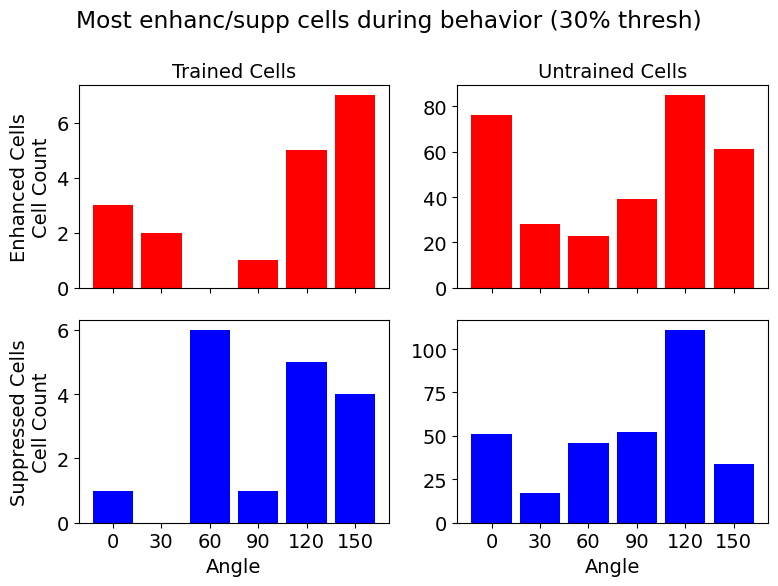

In [10]:
# Plotting histograms of tuning for cells with the largest tuning 
trained_high = index_df.at['trained','high_num']
trained_low = index_df.at['trained','low_num']
untrained_high = index_df.at['untrained','high_num']
untrained_low = index_df.at['untrained','low_num']

fig, axes = plt.subplots(2,2, figsize=(8,6), sharex =True)
width=25

# Plot histograms using dictionary values
one = axes[0, 0].bar(trained_high.keys(), trained_high.values(), width, color='red',label="Amp. During Behav.")
axes[0, 1].bar(untrained_high.keys(), untrained_high.values(), width, color='red')
two = axes[1, 0].bar(trained_low.keys(), trained_low.values(), width, color='blue',label="Sup. During Behav.")
axes[1, 1].bar(untrained_low.keys(), untrained_low.values(), width, color='blue')
axes[1,0].set_xlabel("Angle"); axes[1,1].set_xlabel("Angle"); axes[1,0].set_xticks([0, 30, 60, 90, 120, 150])
    
# Set row labels
axes[0, 0].set_ylabel("Enhanced Cells\nCell Count", fontsize=14)
axes[1, 0].set_ylabel("Suppressed Cells\nCell Count", fontsize=14)

# Set column labels
axes[0, 0].set_title("Trained Cells", fontsize=14)
axes[0, 1].set_title("Untrained Cells", fontsize=14)
plt.rcParams.update({'font.size': 14})

plt.suptitle("Most enhanc/supp cells during behavior (%i%% thresh)" %int(p_threshold*100))
plt.tight_layout()
plt.savefig(os.path.join(fig_dir,'max_tuning_cells_groups.png'), bbox_inches='tight', dpi=400)
plt.show()

## Outcome and in-behavior response plots

C:\Users\Connor\Repositories\analysisConnor2025\.pixi\envs\default\lib\site-packages\ipykernel_launcher.py:32: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.


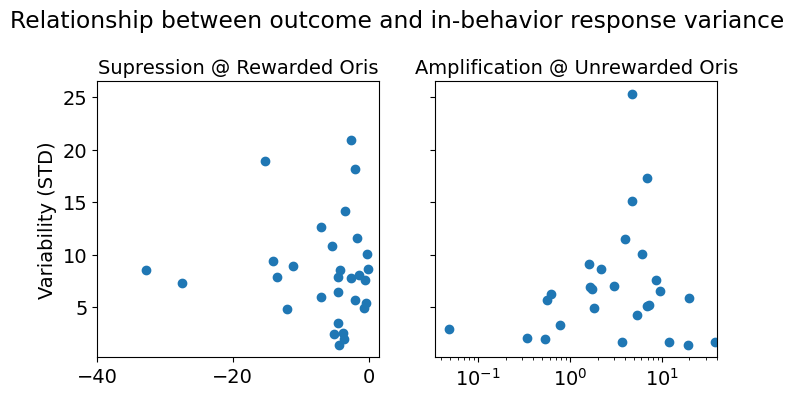

In [11]:
# Plotting a cell's in-behavior variability versus its outcome

# Angle indicies for the averages 
# as a reminder: oris = [0, 30, 60, 90, 120, 150]

rewarded_inds = [2,3,4]
unrewarded_inds = [0,1,5]

# Compute standard deviation as a measure of variability
index_df['Variability'] = index_df['across_days'].apply(lambda x: np.std(x, axis=0))

# Compute the rewarded ori suppression and unrewarded ori amplification, plot variability against this
post_pre_dif_all = dfof_cells_all.at['trained','post']-dfof_cells_all.at['trained','pre']

# Finding indices where rewarded inds were supressed and unrewarded amplified
sup = post_pre_dif_all[:,rewarded_inds].mean(axis=1)
sup_inds = np.where(sup < 0)
amp = post_pre_dif_all[:,unrewarded_inds].mean(axis=1)
amp_inds = np.where(amp > 0)

# Creating plot
fig, axes = plt.subplots(1,2, figsize=(8,4), sharey= True)
fig.subplots_adjust(top=0.8)

axes[0].scatter(sup[sup_inds], index_df.at['trained','Variability'][sup_inds])
axes[1].scatter(amp[amp_inds], index_df.at['trained','Variability'][amp_inds])
axes[1].set_xscale('log')
#axes[1].set_yscale('log')


axes[0].set_ylabel("Variability (STD)"); axes[0].set_title("Supression @ Rewarded Oris", fontsize=14); axes[0].set_xlim(left=-40)
axes[1].set_title("Amplification @ Unrewarded Oris", fontsize =14); axes[1].set_xlim(-5,40)
fig.suptitle("Relationship between outcome and in-behavior response variance")
plt.savefig(os.path.join(fig_dir,'outcome_v_behavior_var.png'), bbox_inches='tight', dpi=400)
plt.show()

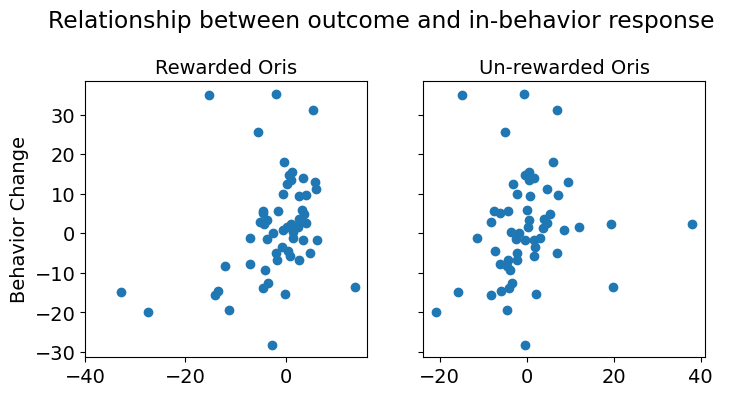

In [12]:
# Plotting a cell's in-behavior response versus its outcome 

# Angle indicies for the averages 
# as a reminder: oris = [0, 30, 60, 90, 120, 150]

rewarded_inds = [2,3,4]
unrewarded_inds = [0,1,5]

# Compute standard deviation as a measure of variability
index_df['Variability'] = index_df['across_days'].apply(lambda x: np.std(x, axis=0))

# Compute the rewarded ori suppression and unrewarded ori amplification, plot variability against this
post_pre_dif_all = dfof_cells_all.at['trained','post']-dfof_cells_all.at['trained','pre']

# Finding indices where rewarded inds were supressed and unrewarded amplified (could be the same cells)
rewarded = post_pre_dif_all[:,rewarded_inds].mean(axis=1)
sup_inds = np.where(sup < 0)
unrewarded = post_pre_dif_all[:,unrewarded_inds].mean(axis=1)
amp_inds = np.where(amp > 0)

# Creating plot
fig, axes = plt.subplots(1,2, figsize=(8,4), sharey= True)
fig.subplots_adjust(top=0.80)

# Diff between first and last day
behav_diff = index_df.at['trained','across_days'][-1,:]-index_df.at['trained','across_days'][0,:]


axes[0].scatter(rewarded, behav_diff)
axes[1].scatter(unrewarded, behav_diff)
axes[0].set_ylabel("Behavior Change"); axes[0].set_title("Rewarded Oris",fontsize=14); axes[0].set_xlim(left=-40)
axes[1].set_title("Un-rewarded Oris", fontsize=14); 
fig.suptitle("Relationship between outcome and in-behavior response ")
plt.savefig(os.path.join(fig_dir,'outcome_v_behavior_resp.png'), bbox_inches='tight', dpi=400)
plt.show()

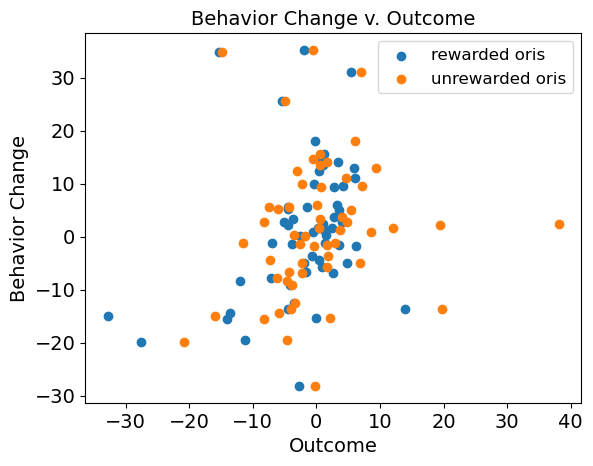

In [13]:
# Plotting a cell's in-behavior response versus its outcome, same as above, but on the same axis

# Angle indicies for the averages 
# as a reminder: oris = [0, 30, 60, 90, 120, 150]

rewarded_inds = [2,3,4]
unrewarded_inds = [0,1,5]

# Compute the rewarded ori suppression and unrewarded ori amplification, plot variability against this
post_pre_dif_all = dfof_cells_all.at['trained','post']-dfof_cells_all.at['trained','pre']

# Finding indices where rewarded inds were supressed and unrewarded amplified (could be the same cells)
rewarded = post_pre_dif_all[:,rewarded_inds].mean(axis=1)
sup_inds = np.where(sup < 0)
unrewarded = post_pre_dif_all[:,unrewarded_inds].mean(axis=1)
amp_inds = np.where(amp > 0)

# Creating plot

# Diff between first and last day
behav_diff = index_df.at['trained','across_days'][-1,:]-index_df.at['trained','across_days'][0,:]

# Plots 
rewarded_plt = plt.scatter(rewarded, behav_diff,label = "rewarded oris")
unrewarded_plt = plt.scatter(unrewarded, behav_diff, label = "unrewarded oris")

# Stats
rew_stat = stats.pearsonr(rewarded, behav_diff)
unrew_stat = stats.pearsonr(unrewarded, behav_diff)

plt.legend(["rewarded oris","unrewarded oris"], fontsize=12)
plt.title("Behavior Change v. Outcome", fontsize=14);
plt.xlabel("Outcome")
plt.ylabel("Behavior Change")
plt.savefig(os.path.join(fig_dir,'outcome_v_behavior_resp_sameax.png'), bbox_inches='tight', dpi=400)
#plt.spines[['right','top']].set_visible(False)
plt.show()

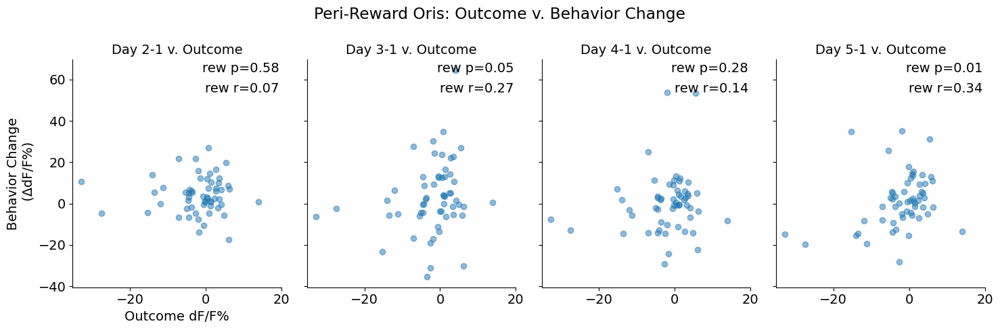

In [155]:
# Plotting a cell's in-behavior response (DIFFERENT DAYS) versus its outcome 

# Angle indicies for the averages 
# as a reminder: oris = [0, 30, 60, 90, 120, 150]

rewarded_inds = [2,3,4]
unrewarded_inds = [0,1,5]

# Compute standard deviation as a measure of variability
index_df['Variability'] = index_df['across_days'].apply(lambda x: np.std(x, axis=0))

# Compute the rewarded ori suppression and unrewarded ori amplification, plot variability against this
post_pre_dif_all = dfof_cells_all.at['trained','post']-dfof_cells_all.at['trained','pre']

# Finding indices where rewarded inds were supressed and unrewarded amplified (could be the same cells)
rewarded = post_pre_dif_all[:,rewarded_inds].mean(axis=1)
sup_inds = np.where(sup < 0)
unrewarded = post_pre_dif_all[:,unrewarded_inds].mean(axis=1)
amp_inds = np.where(amp > 0)

# Creating plot

fig, axes = plt.subplots(1,4, figsize=(15,5), sharey= True, sharex=True)

for day in range(4):

    # Diff between first and next day
    behav_diff = index_df.at['trained','across_days'][day+1,:]-index_df.at['trained','across_days'][0,:]

    # Stats
    rew_stat = stats.spearmanr(rewarded, behav_diff)
    unrew_stat = stats.spearmanr(unrewarded, behav_diff)

    rewarded_plt = axes[day].scatter(rewarded, behav_diff,label = "rewarded oris",alpha = 0.5)
    #unrewarded_plt = axes[day].scatter(unrewarded, behav_diff, label = "unrewarded oris",alpha = 0.5)
    day_next = day+2
    axes[day].set_title("Day %i-%i v. Outcome" % (day_next, 1), fontsize=14);
    axes[day].text(.99,0.99,"rew p=%.2f" %rew_stat.pvalue,ha='right', va='top', transform=axes[day].transAxes)
    #axes[day].text(.99,0.90,"unrew p=%.2f" %unrew_stat.pvalue, ha='right', va='top', transform=axes[day].transAxes)
    axes[0].set_xlabel("Outcome dF/F%")
    axes[0].set_ylabel("Behavior Change\n (ΔdF/F%)")
    #axes[day].set_ylim(-40,40)
    
    axes[day].text(.99,0.9,"rew r=%.2f" %rew_stat.correlation, ha='right', va='top', transform=axes[day].transAxes)
    #axes[day].text(.99,0.71,"unrew r=%.2f" %unrew_stat.statistic, ha='right', va='top', transform=axes[day].transAxes)

    # if day > 0:
    #     axes[day].set_yticks([])

    #axes[day].show()
    axes[day].spines[['right','top']].set_visible(False)
    axes[day].set_xticks([-20,0,20])
plt.suptitle("Peri-Reward Oris: Outcome v. Behavior Change")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir,'peri_rew_outcome_v_behavior_resp_change_daily.png'), bbox_inches='tight', dpi=400)

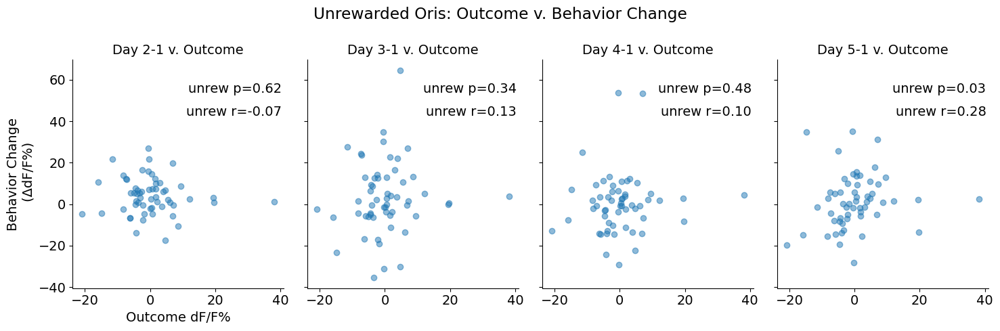

In [14]:
# Same as above but unrewarded, Plotting a cell's in-behavior response (DIFFERENT DAYS) versus its outcome 

# Angle indicies for the averages 
# as a reminder: oris = [0, 30, 60, 90, 120, 150]

rewarded_inds = [2,3,4]
unrewarded_inds = [0,1,5]

# Compute standard deviation as a measure of variability
index_df['Variability'] = index_df['across_days'].apply(lambda x: np.std(x, axis=0))

# Compute the rewarded ori suppression and unrewarded ori amplification, plot variability against this
post_pre_dif_all = dfof_cells_all.at['trained','post']-dfof_cells_all.at['trained','pre']

# Finding indices where rewarded inds were supressed and unrewarded amplified (could be the same cells)
rewarded = post_pre_dif_all[:,rewarded_inds].mean(axis=1)
sup_inds = np.where(sup < 0)
unrewarded = post_pre_dif_all[:,unrewarded_inds].mean(axis=1)
amp_inds = np.where(amp > 0)

# Creating plot

fig, axes = plt.subplots(1,4, figsize=(15,5), sharey= True)

for day in range(4):

    # Diff between first and last day
    behav_diff = index_df.at['trained','across_days'][day+1,:]-index_df.at['trained','across_days'][0,:]

    # Stats
    rew_stat = stats.spearmanr(rewarded, behav_diff)
    unrew_stat = stats.spearmanr(unrewarded, behav_diff)

    #rewarded_plt = axes[day].scatter(rewarded, behav_diff,label = "rewarded oris",alpha = 0.5)
    unrewarded_plt = axes[day].scatter(unrewarded, behav_diff, label = "unrewarded oris",alpha = 0.5)
    day_next = day+2
    axes[day].set_title("Day %i-%i v. Outcome" % (day_next, 1), fontsize=14);
    #axes[day].text(.99,0.99,"rew p=%.2f" %rew_stat.pvalue,ha='right', va='top', transform=axes[day].transAxes)
    axes[day].text(.99,0.90,"unrew p=%.2f" %unrew_stat.pvalue, ha='right', va='top', transform=axes[day].transAxes)
    axes[0].set_xlabel("Outcome dF/F%")
    axes[0].set_ylabel("Behavior Change\n (ΔdF/F%)")
    #axes[day].set_ylim(-40,40)
    
    #axes[day].text(.99,0.9,"rew r=%.2f" %rew_stat.statistic, ha='right', va='top', transform=axes[day].transAxes)
    axes[day].text(.99,0.80,"unrew r=%.2f" %unrew_stat.correlation, ha='right', va='top', transform=axes[day].transAxes)

    # if day > 0:
    #     axes[day].set_yticks([])

    #axes[day].show()
    axes[day].spines[['right','top']].set_visible(False)
    #axes[day].set_xticks([-30,0,30])
    
plt.suptitle("Unrewarded Oris: Outcome v. Behavior Change")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir,'unrew_outcome_v_behavior_resp_change_daily.png'), bbox_inches='tight', dpi=400)


## Behavior Trajectory Sorting
Code that sorts cells by how their in-behavior response to manip ori changes, **note:** currently the code only filters on day-by-day comparison. One thing to add would be another condition that checks if a go-up cell has a postive change between the first and the last day.

In [15]:
# Sectioning timecourse data into three groups, currently code only filters on day-by-day comparison
# Slowly go down over behavior 
# Slowly go up 
# Up down up 

# Need to try different criteria where go-up cells are classified by 2 or 3 days of '+' and end value that is greater than the beginning value 

# Threshold for change, update this value to affect how the cells are grouped
thresh = 8

# Defining data frame to store the coding for change between days
diff_code = np.zeros((index_df.at['trained','across_days'].shape[0]-1,index_df.at['trained','across_days'].shape[1])).astype('str')

for day in range(4): # Only 4 since it is one minus the number of behavior days 
    # Change between two days
    diff = index_df.at['trained','across_days'][day+1,:] - index_df.at['trained','across_days'][day,:]
    
    up = np.where(diff>thresh)
    no_change = np.where((thresh>diff) & (diff>-thresh))
    down = np.where(diff<-thresh)
    
    diff_code[day,up] = '+'
    diff_code[day,down] = '-'
    diff_code[day,no_change] = 'none'

# Storing cells which go up or don't change and cells that go down and don't change
go_up = np.all(np.isin(diff_code,['+','none']),axis=0)
go_down = np.all(np.isin(diff_code,['-','none']),axis=0)

# Finding cells where middle behavior day is less than the day before and after it 
data = index_df.at['trained','across_days']
dip_mid = (data[1,:] > data[2,:]) & (data[3,:] > data[2,:])
pop_mid = (data[1,:] < data[2,:]) & (data[3,:] < data[2,:])
other_cells = ~(go_up | go_down | dip_mid | pop_mid)

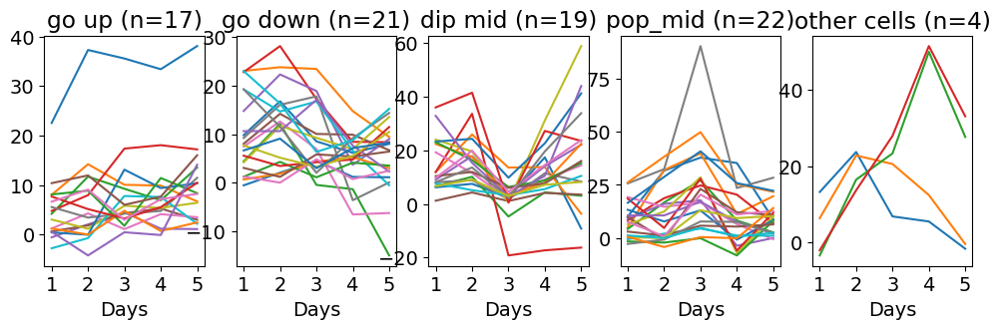

In [16]:
# Plotting groups to check catergorization
fig ,axes = plt.subplots(1,5,figsize=(12,3))
titles = ["go up","go down","dip mid","pop_mid","other cells"]
for i,inds in enumerate([go_up,go_down,dip_mid,pop_mid,other_cells]):
    ax = axes[i]
    ax.plot(index_df.at['trained','across_days'][:,inds])
    ax.set_title(titles[i] + ' (n=%i)' %len(np.where(inds)[0]))
    ax.set_xticks([0,1,2,3,4])
    ax.set_xticklabels([1,2,3,4,5])
    ax.set_xlabel("Days")


## Other sorting methods (testing stuff out)

        Trend
0  Decreasing
1  Decreasing
2  Decreasing
3  Decreasing
4  Decreasing
5  Increasing
6  Decreasing
7  Decreasing
8  Decreasing
9  Decreasing


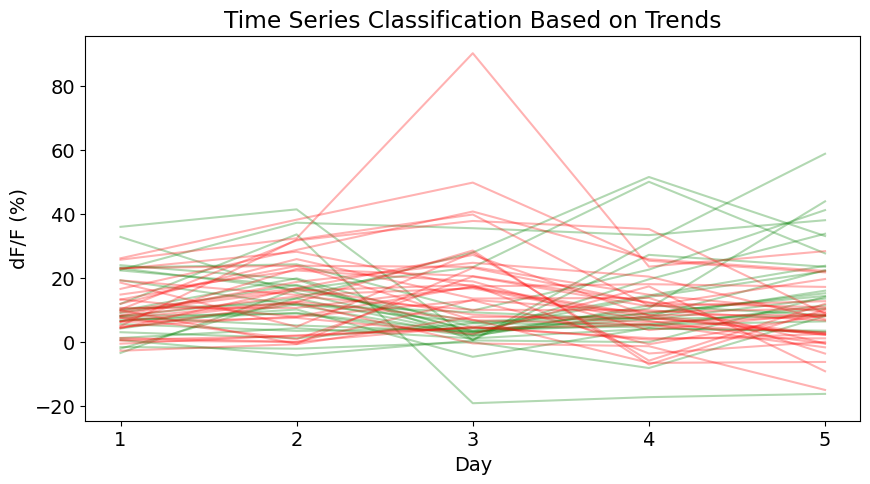

In [17]:
# Transpose data so each row is a time series
data = index_df.at['trained','across_days']
data_t = data.T

# Convert to DataFrame for easier manipulation
df = pd.DataFrame(data_t)

# Apply rolling mean to smooth each time series, probably a silly step since only 5 data points
window_size =2  # Rolling window size
df_smooth = df.rolling(window=window_size, axis=1, min_periods=1).mean()

# Compute first difference to detect trend direction
df_diff = df_smooth.diff(axis=1)

# Classify trends based on final difference value, stationary removed for now
trend_labels = np.where(df_diff.iloc[:, -1] > 0, "Increasing", 
                        np.where(df_diff.iloc[:, -1] < 0, "Decreasing", "Stationary"))

# Add classification labels to the DataFrame
df["Trend"] = trend_labels

# Print first 10 classifications
print(df[["Trend"]].head(10))

# Plot grouped time series based on trends
fig,ax = plt.subplots(figsize=(10, 5))

for trend, color in zip(["Increasing", "Decreasing", "Stationary"], ['g', 'r', 'b']):
    subset = df[df["Trend"] == trend].iloc[:, :-1].T  # Exclude the trend label column
    ax.plot(subset, color=color, alpha=0.3, label=trend if trend not in plt.gca().get_legend_handles_labels()[1] else "")

ax.set_xlabel("Day")
ax.set_ylabel("dF/F (%)")
ax.set_xticks([0,1,2,3,4])
ax.set_xticklabels([1,2,3,4,5])
plt.title("Time Series Classification Based on Trends")
# plt.legend()
plt.show()

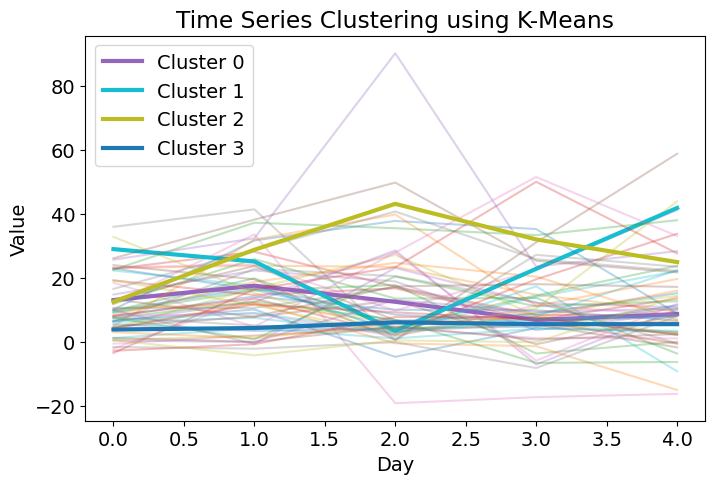

In [18]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Standardize each feature for better clustering
data_t = index_df.at['trained','across_days'].T
scaler = StandardScaler()
data_scaled = scaler.fit_transform(index_df.at['trained','across_days'].T)
n_features = 5 

# Apply K-Means clustering
num_clusters = 4  # Choose the number of clusters
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
labels = kmeans.fit_predict(data_scaled)

# Plot representative time series from each cluster
plt.figure(figsize=(8, 5))
for cluster in range(num_clusters):
    cluster_series = data_t[labels == cluster]  # Extract series belonging to the cluster
    for series in cluster_series:
        plt.plot(range(n_features), series, alpha=0.3)  # Plot each series in the cluster
    plt.plot(range(n_features), np.mean(cluster_series, axis=0), linewidth=3, label=f'Cluster {cluster}')

plt.xlabel("Day")
plt.ylabel("Value")
plt.title("Time Series Clustering using K-Means")
plt.legend()
plt.show()